# 05a. Small LLM with LoRA (Qwen3-0.6B)

Tests whether a small decoder LLM, fine-tuned with LoRA on the same features written as text, does better than the encoder models. Qwen3-0.6B is about four times the size of ModernBERT. It was trained and scored on Kaggle because it does not fit the laptop's 6 GB GPU: training in `05b_qwen_lora_train_kaggle.ipynb`, scoring in `05c_qwen_lora_score_kaggle.ipynb`. This notebook loads their saved results, logs them to MLflow and records the findings.

c:\SAP\Projects\Bankguard\bank-guard\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


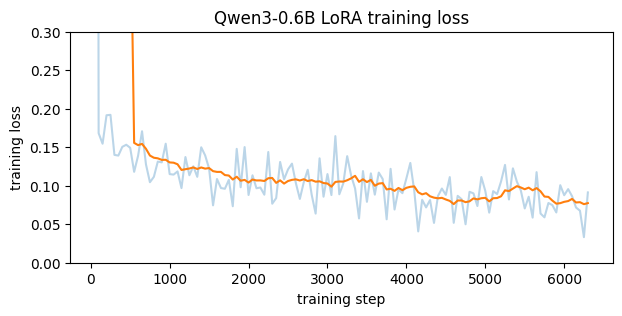

,tags.mlflow.runName,metrics.pr_auc,metrics.recall_at_0.1pct_fpr,metrics.recall_at_1.0pct_fpr
2,"Sequence model, seed 7",0.4820,0.5396,0.8349
3,"Sequence model, seed 42",0.4544,0.5241,0.8292
1,"Sequence model, seed 123",0.4338,0.4913,0.8137
5,"TabPFN-3.5-Fast, context 200,000",0.3985,0.3967,0.7963
6,"ModernBERT, 4 epochs",0.3526,0.3755,0.7606
9,"LightGBM, owner attributes",0.3412,0.3793,0.7635
0,"Qwen3-0.6B LoRA, same features as text",0.3060,0.3571,0.7635
7,"ModernBERT, same features as text",0.3023,0.3600,0.7828
8,"DistilBERT, same features as text",0.2281,0.2963,0.7259


In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import mlflow
import pandas as pd

QWEN = Path("../models/qwen")
metrics = json.loads((QWEN / "qwen_metrics.json").read_text())
log = json.loads((QWEN / "qwen_train_log.json").read_text())
curve = pd.DataFrame([row for row in log["log_history"] if "loss" in row])

mlflow.set_tracking_uri("sqlite:///../mlflow.db")
mlflow.set_experiment("bankguard-laundering")
with mlflow.start_run(run_name=metrics["model"]):
    mlflow.log_params({
        "model_name": "Qwen/Qwen3-0.6B", "method": "LoRA", "lora_r": 16, "lora_alpha": 32,
        "lora_dropout": 0.05, "target_modules": "q_proj,k_proj,v_proj,o_proj",
        "trainable_params": 4_589_568, "epochs": 1, "batch_size": 32, "learning_rate": 1e-4,
        "weight_decay": 0.01, "warmup_steps": 100, "max_len": 192, "train_rows": 202_530,
        "seed": 42,
    })
    for key in ["pr_auc", "recall_at_0.1%_fpr", "recall_at_1.0%_fpr"]:
        mlflow.log_metric(key.replace("%", "pct"), metrics[key])
    mlflow.log_metrics({"train_minutes": log["train_minutes"], "score_minutes": metrics["score_minutes"]})
    for row in curve.itertuples():
        mlflow.log_metric("train_loss", row.loss, step=int(row.step))
    mlflow.log_artifact(QWEN / "qwen_metrics.json")
    mlflow.log_artifact(QWEN / "qwen_train_log.json")
    mlflow.set_tags({
        "trained_on": "Kaggle, two Tesla T4",
        "notebook": "notebooks/05b_qwen_lora_train_kaggle.ipynb, notebooks/05c_qwen_lora_score_kaggle.ipynb",
    })

ax = curve.plot(x="step", y="loss", alpha=0.3, legend=False, figsize=(7, 3))
curve["loss"].rolling(10).mean().set_axis(curve["step"]).plot(ax=ax)
ax.set(xlabel="training step", ylabel="training loss", ylim=(0, 0.3), title="Qwen3-0.6B LoRA training loss")
plt.show()

mlflow.search_runs(experiment_names=["bankguard-laundering"])[
    ["tags.mlflow.runName", "metrics.pr_auc", "metrics.recall_at_0.1pct_fpr", "metrics.recall_at_1.0pct_fpr"]
].dropna().sort_values("metrics.pr_auc", ascending=False).round(4)

Qwen3-0.6B with LoRA reaches validation PR-AUC 0.306, recall 0.357 at a 0.1% false positive rate and 0.764 at 1%. It is about level with ModernBERT after two epochs (0.302, 0.360, 0.783) and below ModernBERT after four epochs (0.353), LightGBM (0.341), TabPFN-3.5-Fast (0.398) and the sequence model (0.486 as the average of three seeds). Four times the parameters of ModernBERT bring no gain: the inputs are 22 numbers written as text, so pretraining on language adds little, and LoRA trains only 0.76% of the weights.

It was trained for one epoch, against two and four for ModernBERT, and the training loss was still falling slowly at the end, so a longer run might gain a few points. It was not pursued: each attempt costs about 4 hours of training and 6 hours of scoring on Kaggle, and every text model so far sits below the models that read the features or the transaction history directly. The text approach is therefore closed here, and Qwen remains in the comparison as run.